# Per-garden GWAS — every non-SNP / SV Bonferroni hit across gardens (dot grid)

**All** Bonferroni-significant non-SNP and SV hits are shown, not just the SNP-blind ones. One dot
per (gene, garden) whose tiling block carries a Bonferroni-significant non-SNP/SV lead in that
garden. Layout follows `newpeak_dotgrid_lfmm_nonsnp.ipynb`, with **gardens as columns ordered
cold → hot** instead of climate axes.

- **dot size** = −log10 p of the block's lead record
- **dot colour** = TAIR-GO + UniProt functional category
- **open black ring around the dot** = the hit is **SNP-blind**: no SNP in the same tiling block
  clears the SNP genome-wide Bonferroni in that same garden
- **no ring** = the SNP scan is *also* significant in that block. These are **kept and drawn at
  full strength** — SNP overlap is a label here, not a filter
- **right-hand bar** = |alt_len − ref_len| for the lead variant, log scale; rows ordered by size
- **row label** = `SYMBOL (AGI)` where TAIR/UniProt gives a usable symbol, bare AGI otherwise
- **† + grey italic row label** = every lead variant on that row falls **outside** the gene body;
  the gene is on the row only because it shares a tiling block with the variant

### Row labels: symbol where there is one

Symbols come from the mandated annotator (`annotate_genes_tair_uniprot.py`, TAIR GO + UniProt),
cached to `persite_newpeak_gene_annotation.csv` so a rebuild does not re-hit the API. The AGI is
kept in parentheses so the locus id stays discoverable.

UniProt's `gene_primary` is sometimes a **BAC/TAC clone ORF id** (`MDF20.19`, `MJE7.5`, `MEE6.3`)
rather than a real symbol, and those are less recognisable than the AGI. But the same
`LETTERS+DIGIT.DIGIT` shape is also worn by genuine family symbols (`GLR1.2`, `GLR1.3`), so a bare
regex would throw those away too. **Rule used:** reject a clone-shaped candidate *only when it is
uncorroborated* — no curated TAIR name **and** not a reviewed (Swiss-Prot) entry. The rejected
candidates are printed below so the call is auditable.

### ⚠️ Adjacent rows are often ONE variant, not several loci

A tiling block spans several genes, so a single significant variant is drawn once **per gene in
the block** — identical dot patterns on adjacent rows are the *same* observation, not replication.
The clearest case: the three most-recurrent SV rows, **UUAT1 (AT5G04160) / CML50 (AT5G04170) /
ACA3 (AT5G04180)**, are one variant — `chr5:1,146,373`, a 94 bp deletion in block `Chr5_835`. It
is the only SV-class marker Bonferroni-significant in 13 gardens genome-wide and the only SV-scan
marker anywhere in the 6.5 kb those three genes span (Chr5:1,142,782–1,149,284). Only **CML50**
actually contains it (intron 1); UUAT1 is 1,461 bp away and ACA3 is 1,275 bp away, so both carry
the † passenger mark. The `AT1G24620`/`AT1G24625` and `AT3G26280`/`AT3G26290` pairs are the same
pattern; the audit table printed below enumerates every such group.

### The "overlaps a SNP hit" rule

Block-based, not a distance window: a class hit overlaps a SNP hit iff the **lead SNP record in
the same unmerged clq r² = 0.9 tiling block, in the same garden**, clears the SNP genome-wide
Bonferroni 0.05/n_snp. This is the rule `class_hits()` (formerly `new_peaks()`) has always used;
it is now surfaced as `SNP_OVERLAP_RULE`. The tiling partition is *unmerged*, so a block id means
the same interval for the SNP and the class scan — see the builder docstring for why
`merge_small_blocks` must not be used here.

### Thresholds — the two panels are separate, not unioned

The three class scans have very different marker counts, so their genome-wide Bonferroni cut-offs
differ (≈7.55 / 7.02 / 5.41 in −log10 p for snp / nonsnp / sv). **`nonsnp` is smallindel + SV
pooled, so it overlaps the `sv` scan**: the same variant can clear the (looser) SV threshold and
miss the (stricter) non-SNP one. The two grids below are therefore shown side by side and never
unioned, so no marker is counted twice.

> ⚠️ One dot per **(block, garden)**, placed at the block's lead record. Where a block carries
> more than one significant marker in a garden they collapse into that single dot; the cell count
> printed below is therefore smaller than the raw marker-hit count, and `n_sig_in_block` in the
> exported CSV records how many collapsed.

> ⚠️ Variant size comes from the panel meta (`|alt_len − ref_len|`, max over records at that
> position). The GEMMA arrays carry only chrom/pos, so for the ~2.1% of positions that are
> multiallelic the size is the largest allele at the position, not necessarily the tested one.

> ⚠️ Cross-garden recurrence here is **descriptive, not a tested contrast** — the cross-garden
> test was the meta this analysis deliberately dropped, and all 30 gardens share one founder
> panel and one `p0`, so their scans are correlated by construction. Low-frequency markers also
> dominate the underlying hit list (see the MAC caveat in `persite_gwas.ipynb`).

In [1]:

import os, sys
import numpy as np, pandas as pd
from scipy import stats
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.lines as mlines
os.chdir("/global/scratch/projects/fc_moilab/tbellg/kmate")
sys.path.insert(0, "analysis/grenenet_selection")
sys.path.insert(0, "analysis/grenenet_selection/blocks")
import lib, blocks_tiling as bt
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

RES = "analysis/grenenet_selection/r3_persite_gwas/results/gemma_gwas"
PLOTS = f"{RES}/plots"; os.makedirs(PLOTS, exist_ok=True)
CH = ["Chr1", "Chr2", "Chr3", "Chr4", "Chr5"]

def load(name):
    d = np.load(f"{RES}/persite_gwas_{name}.npz", allow_pickle=True)
    chrom = np.array([c.replace("chr", "Chr") for c in d["chrom"].astype(str)])
    pos = d["pos"].astype(np.int64)
    # UNMERGED tiling: fixed by panel LD, so identical across classes -- see builder docstring
    blk = np.asarray(bt.assign_tiling(chrom, pos, r2=0.9), dtype=object)
    return dict(chrom=chrom, pos=pos, P=d["P"], blk=blk,
                sites=[int(s) for s in d["sites"]], bio1=d["bio1"].astype(float))

SNP = load("snp")
sites = SNP["sites"]; bio1 = SNP["bio1"]
site_bio1 = {s: float(b) for s, b in zip(sites, bio1)}
site_order = sorted(sites, key=lambda s: site_bio1[s])          # cold -> hot
GENES = lib.load_genes()

# gene body spans, keyed by the SAME identifier genes_on() emits, so a hit can be asked
# "does this variant actually sit inside the gene, or was it only block-attributed?"
_GCOL = "symbol" if "symbol" in GENES.columns else GENES.columns[-1]
GENE_SPAN = {}
for _c, _lo, _hi, _k in zip(GENES.chrom.astype(str).str.replace("chr", "Chr"),
                            GENES.start, GENES.end, GENES[_GCOL].astype(str)):
    _prev = GENE_SPAN.get(_k)
    GENE_SPAN[_k] = ((_c, int(_lo), int(_hi)) if _prev is None else
                     (_prev[0], min(_prev[1], int(_lo)), max(_prev[2], int(_hi))))

CHROM_LEN = {c: int(SNP["pos"][SNP["chrom"] == c].max()) for c in CH}
OFF, _cum = {}, 0
for c in CH:
    OFF[c] = _cum; _cum += CHROM_LEN[c]
GENOME = _cum

def gpos(chrom, pos):
    return np.array([OFF[c] for c in chrom]) + pos

def genes_on(blk_id, d):
    """Gene symbols overlapping a block's span (+/-2 kb promoter)."""
    m = d["blk"] == blk_id
    if not m.any():
        return []
    ch = d["chrom"][m][0]; lo, hi = d["pos"][m].min() - 2000, d["pos"][m].max() + 2000
    g = GENES[(GENES.chrom.astype(str).str.replace("chr", "Chr") == ch) &
              (GENES.end > lo) & (GENES.start < hi)]
    col = "symbol" if "symbol" in g.columns else g.columns[-1]
    return [str(x) for x in g[col].dropna().unique()[:4]]

print(f"{len(sites)} gardens, bio1 {bio1.min():.1f}-{bio1.max():.1f} C; "
      f"snp {len(SNP['pos']):,} markers")


30 gardens, bio1 6.0-21.6 C; snp 1,752,846 markers


In [2]:

def lam_gc(p):
    p = np.clip(np.asarray(p, float), 1e-300, 1.0)
    p = p[np.isfinite(p)]
    return float(np.median(stats.chi2.isf(p, 1)) / stats.chi2.isf(0.5, 1))

def qq_xy(p, keep_head=8000, n_bulk=2500):
    """Observed vs expected -log10p; keep the whole significant tail, thin the dense bulk."""
    p = np.sort(np.clip(np.asarray(p, float)[np.isfinite(p)], 1e-300, 1.0))
    n = len(p)
    exp = -np.log10((np.arange(n) + 0.5) / n); obs = -np.log10(p)
    if n <= keep_head + n_bulk:
        idx = np.arange(n)
    else:
        idx = np.concatenate([np.arange(keep_head),
                              np.unique(np.geomspace(keep_head, n - 1, n_bulk).astype(int))])
    return exp[idx], obs[idx]

def leads(d, si):
    """Per block, the record with the smallest p in garden si. Returns DataFrame."""
    p = d["P"][:, si]
    ok = np.isfinite(p)
    df = pd.DataFrame(dict(blk=d["blk"][ok], chrom=d["chrom"][ok], pos=d["pos"][ok],
                           nlp=-np.log10(np.clip(p[ok], 1e-300, 1))))
    return df.loc[df.groupby("blk")["nlp"].idxmax()]

# The one rule for "this hit overlaps a SNP hit", used by every panel below. It is a
# BLOCK rule, not a distance window: two records overlap iff they land in the same unmerged
# clq r2=0.9 tiling block (identical partition for every class -- see builder docstring) in
# the SAME garden, and the SNP scan's lead record in that block clears the SNP genome-wide
# Bonferroni 0.05/n_snp for that garden. Predates this notebook; it is the definition
# `new_peaks()` has always used.
SNP_OVERLAP_RULE = ("same unmerged clq r2=0.9 tiling block, same garden, SNP lead record "
                    "over the SNP genome-wide Bonferroni 0.05/n_snp")

def class_hits(cd, si, snp_lead=None):
    """EVERY block whose CLASS lead clears that class's genome-wide Bonferroni in garden `si`.

    Returns (df, bs, bc). `df.snp_also` flags the ones that also carry a Bonferroni-significant
    SNP lead in the same block (SNP_OVERLAP_RULE) -- it is a LABEL, not a filter. Callers that
    want only the SNP-blind subset take `df[~df.snp_also]` themselves.
    """
    sl = leads(SNP, si) if snp_lead is None else snp_lead
    cl = leads(cd, si)
    bs = -np.log10(0.05 / np.isfinite(SNP["P"][:, si]).sum())
    bc = -np.log10(0.05 / np.isfinite(cd["P"][:, si]).sum())
    m = cl.merge(sl[["blk", "nlp"]], on="blk", how="left", suffixes=("", "_snp"))
    m["nlp_snp"] = m["nlp_snp"].fillna(0.0)
    m["snp_also"] = m["nlp_snp"] > bs
    return m[m["nlp"] > bc].copy(), bs, bc

new_peaks = class_hits          # back-compat alias: same function, franker name

SNP_DARK, SNP_LIGHT = "#3B3B3B", "#9A9A9A"
CLS_COL = {"nonsnp": ("#C1560F", "#E8A87C"), "sv": ("#2E7D32", "#88C68B")}


## Collect every Bonferroni hit and its genes

In [3]:

# EVERY Bonferroni-significant block-garden cell, for BOTH the non-SNP and the SV scan.
# Nothing is filtered on SNP overlap here: `snp_also` is carried as a label and becomes the
# ring/no-ring distinction in the plot.
print("overlap rule:", SNP_OVERLAP_RULE, "\n")
ALL, THRESH = [], []
for CLS in ["nonsnp", "sv"]:
    CD = load(CLS)
    n_marker_hits, bcs = 0, []
    for s in site_order:
        si = sites.index(s)
        hits, bs, bc = class_hits(CD, si)
        bcs.append(bc)
        pc = -np.log10(np.clip(CD["P"][:, si], 1e-300, 1))
        sig = np.isfinite(pc) & (pc > bc)              # raw marker-level hits, for the audit below
        n_marker_hits += int(sig.sum())
        per_blk = pd.Series(CD["blk"][sig]).value_counts()
        for _, r in hits.iterrows():
            gl = genes_on(r.blk, CD) or [r.blk]
            for g in gl:
                # does the lead variant sit INSIDE this gene, or was the gene only pulled in by
                # the block? (a block spans several genes, so most rows in a multi-gene block
                # are attribution passengers, not independent hits)
                sp_ = GENE_SPAN.get(g)
                if sp_ is None or sp_[0] != r.chrom:
                    has_gene, in_gene, dist = (sp_ is not None), False, np.nan
                else:
                    has_gene = True
                    in_gene = sp_[1] <= int(r.pos) <= sp_[2]
                    dist = 0 if in_gene else int(min(abs(int(r.pos) - sp_[1]),
                                                     abs(int(r.pos) - sp_[2])))
                ALL.append(dict(cls=CLS, garden=s, bio1=site_bio1[s], blk=r.blk, gene=g,
                                chrom=r.chrom, pos=int(r.pos), nlp=float(r.nlp),
                                nlp_snp=float(r.nlp_snp), snp_also=bool(r.snp_also),
                                n_sig_in_block=int(per_blk.get(r.blk, 1)),
                                n_genes_in_block=len(gl), has_gene=has_gene,
                                in_gene=bool(in_gene), dist_to_gene_bp=dist))
    # the threshold is per-garden (0.05 / #markers with a finite p in THAT garden), so report
    # the range rather than pretend it is one number
    THRESH.append(dict(cls=CLS, n_markers=len(CD["pos"]),
                       bonf_nlp=f"{min(bcs):.3f}-{max(bcs):.3f}", marker_hits=n_marker_hits))
ALL = pd.DataFrame(ALL)
ALL.to_csv(f"{RES}/persite_newpeak_genes.csv", index=False)   # filename kept: genes/README.md reads it

print(pd.DataFrame(THRESH).to_string(index=False))
print("\n(bonf_nlp is that class's own genome-wide 0.05/n; nonsnp = smallindel+sv POOLED, so it "
      "overlaps\n the sv scan and its threshold is the stricter of the two -- the two panels are "
      "shown separately\n and are NOT unioned, so no marker is double-counted.)\n")

cells = ALL.drop_duplicates(["cls", "blk", "garden"])
print(f"{len(cells)} (block, garden) cells plotted -> {len(ALL)} (gene, garden) dots "
      f"across {ALL.gene.nunique()} genes")
print(cells.groupby(["cls", "snp_also"]).size().rename("cells").to_string())
print("\ncircled (SNP-blind) vs plain (SNP hit in the same block), gene-expanded dots:")
print(ALL.groupby(["cls", "snp_also"]).size().rename("dots").to_string())
print(f"\nblocks carrying >1 significant marker in a garden: "
      f"{int((cells.n_sig_in_block > 1).sum())}/{len(cells)} -- those collapse to one dot at the "
      f"block LEAD, so marker_hits above exceeds the cell count by design.")

# ---- one variant, several gene rows: the block-attribution passenger audit -------------
# A tiling block can span several genes, so ONE significant variant produces one ROW PER GENE
# with an identical dot pattern. Rows whose gene does not actually contain the lead variant are
# passengers of that attribution, not independent hits.
print(f"\n{int((~ALL.in_gene & ALL.has_gene).sum())}/{int(ALL.has_gene.sum())} gene-expanded "
      f"dots sit OUTSIDE the gene they are drawn against (block-attribution passengers); "
      f"{int((~ALL.has_gene).sum())} dots have no gene at all and are labelled by block id.")
multi = (ALL[ALL.n_genes_in_block > 1]
         .groupby(["cls", "blk", "chrom", "pos"])
         .agg(gardens=("garden", "nunique"),
              genes=("gene", lambda s: ", ".join(sorted(set(s)))),
              contains=("gene", lambda s: ", ".join(sorted(
                  set(ALL.loc[s.index][ALL.loc[s.index].in_gene].gene))) or "NONE"))
         .reset_index().sort_values("gardens", ascending=False))
print(f"\n{len(multi)} (class, block, lead-variant) groups attribute ONE variant to >1 gene "
      f"-- the rows below are NOT independent loci:")
print(multi.head(12).to_string(index=False))


overlap rule: same unmerged clq r2=0.9 tiling block, same garden, SNP lead record over the SNP genome-wide Bonferroni 0.05/n_snp 



   cls  n_markers    bonf_nlp  marker_hits
nonsnp     525043 7.021-7.021          113
    sv      12789 5.408-5.408           37

(bonf_nlp is that class's own genome-wide 0.05/n; nonsnp = smallindel+sv POOLED, so it overlaps
 the sv scan and its threshold is the stricter of the two -- the two panels are shown separately
 and are NOT unioned, so no marker is double-counted.)

130 (block, garden) cells plotted -> 293 (gene, garden) dots across 148 genes
cls     snp_also
nonsnp  False       76
        True        17
sv      False       35
        True         2

circled (SNP-blind) vs plain (SNP hit in the same block), gene-expanded dots:
cls     snp_also
nonsnp  False       175
        True         39
sv      False        75
        True          4

blocks carrying >1 significant marker in a garden: 10/130 -- those collapse to one dot at the block LEAD, so marker_hits above exceeds the cell count by design.

238/277 gene-expanded dots sit OUTSIDE the gene they are drawn against (block-a

## Variant size and functional category

In [4]:

# variant size (bp) per position, from the SAME panel meta the scan was built from
SIZE = {}
for _ci in range(1, 6):
    _m = np.load(f"{lib.PROJ}/panel/arch3/chr{_ci}/var_pa_231_arch3_chr{_ci}.meta.npz",
                 allow_pickle=True)
    _p = _m["pos"].astype(np.int64)
    _d = np.abs(_m["alt_len"].astype(int) - _m["ref_len"].astype(int))
    for q, dd in zip(_p, _d):                       # max per pos (multiallelic)
        k = (f"Chr{_ci}", int(q))
        if dd > SIZE.get(k, -1):
            SIZE[k] = int(dd)
ALL["size_bp"] = [SIZE.get((c, p), np.nan) for c, p in zip(ALL.chrom, ALL.pos)]
print(f"size attached for {ALL.size_bp.notna().mean():.1%} of cells; "
      f"median {ALL.size_bp.median():.0f} bp, max {ALL.size_bp.max():.0f} bp")


size attached for 100.0% of cells; median 5 bp, max 7341 bp


In [5]:

# Gene SYMBOL + functional category -- TAIR GO + UniProt (the annotator mandated in CLAUDE.md).
# CACHED to a CSV under this section's results/, so a rebuild only hits the API for genes that
# are not in the cache yet. Degrades to AGI-only / "unclassified" if outbound HTTPS is down.
import re
ANN_CACHE = f"{RES}/persite_newpeak_gene_annotation.csv"
genes = sorted(ALL.gene.unique())

cache = pd.read_csv(ANN_CACHE) if os.path.exists(ANN_CACHE) else pd.DataFrame(columns=["gene"])
have = set(cache.gene.astype(str)) if len(cache) else set()
need = [g for g in genes if g not in have]
print(f"{len(genes)} genes | {len(genes) - len(need)} from cache ({ANN_CACHE}) | {len(need)} to fetch")
if need:
    try:
        import importlib.util as _ilu
        _p = "analysis/grenenet_selection/r2_gea_nonsnp/phase1_replication/annotate_genes_tair_uniprot.py"
        if not os.path.exists(_p):
            _p = "analysis/grenenet_selection/archive_gea/phase1_replication/annotate_genes_tair_uniprot.py"
        _s = _ilu.spec_from_file_location("ann", _p); ann = _ilu.module_from_spec(_s)
        _s.loader.exec_module(ann)
        print("annotator loaded:", _p)
        fresh = ann.annotate(need)
        cache = pd.concat([cache, fresh], ignore_index=True) if len(cache) else fresh
        cache.to_csv(ANN_CACHE, index=False)
        print(f"cache updated -> {len(cache)} genes")
    except Exception as e:
        print(f"  annotation unavailable -> {type(e).__name__}: {e} (falling back to AGI labels)")

res = cache[cache.gene.astype(str).isin(genes)] if len(cache) else cache

# ---- symbol quality rule ---------------------------------------------------------------
# UniProt `gene_primary` is sometimes a BAC/TAC clone ORF id (MDF20.19, MJE7.5, MEE6.3) rather
# than a real symbol -- those are LESS recognisable than the AGI, so we drop them. But the same
# LETTERS+DIGIT.DIGIT shape is also worn by genuine family symbols (GLR1.2, GLR1.3), so the
# regex alone is not safe. Rule used: reject a clone-shaped candidate ONLY when it is
# uncorroborated -- no curated TAIR name AND not a reviewed (Swiss-Prot) entry.
CLONE_RE = re.compile(r"^[A-Za-z]{1,5}\d+[A-Za-z]?\.\d+$")

def usable_symbol(sym, agi, tair_name, reviewed):
    """-> (symbol_or_None, why_not). why_not is 'none' / 'is_agi' / 'clone_id'."""
    s = "" if sym is None or (isinstance(sym, float) and np.isnan(sym)) else str(sym).strip()
    if not s or s.lower() == "nan":
        return None, "none"
    if s.upper() == str(agi).upper():
        return None, "is_agi"
    curated = str(tair_name).strip() not in ("", "nan")
    if CLONE_RE.match(s) and not curated and str(reviewed) != "True":
        return None, "clone_id"
    return s, ""

CATS, SYM, NAME = {}, {}, {}
clone_rej, no_sym = [], 0
for r in res.itertuples():
    CATS[r.gene] = (str(r.categories).split(",")[0]
                    if str(getattr(r, "categories", "")).strip() not in ("", "nan")
                    else "unclassified")
    NAME[r.gene] = getattr(r, "protein_name", "")
    s, why = usable_symbol(getattr(r, "symbol", None), r.gene,
                           getattr(r, "tair_name", ""), getattr(r, "uniprot_reviewed", ""))
    if s:
        SYM[r.gene] = s
    elif why == "clone_id":
        clone_rej.append(f"{r.gene}<-{r.symbol}")
    else:
        no_sym += 1

ALL["category"] = [CATS.get(g, "unclassified") for g in ALL.gene]
ALL["symbol"] = [SYM.get(g, "") for g in ALL.gene]
# axis label: SYMBOL (AGI) so the symbol is readable and the locus id stays discoverable
ALL["label"] = [f"{SYM[g]} ({g})" if g in SYM else str(g) for g in ALL.gene]

print(f"\nsymbols resolved for {ALL.loc[ALL.symbol != '', 'gene'].nunique()}/{ALL.gene.nunique()} "
      f"genes  |  {no_sym} genes have no symbol at all (AGI kept)  |  "
      f"{len(clone_rej)} clone-shaped candidates rejected in favour of the AGI:")
print("   " + (", ".join(clone_rej) if clone_rej else "(none)"))
print(f"\ncategories assigned: {(ALL.category != 'unclassified').sum()}/{len(ALL)} cells, "
      f"{ALL.loc[ALL.category != 'unclassified', 'gene'].nunique()}/{ALL.gene.nunique()} genes")
print(ALL.drop_duplicates('gene').category.value_counts().to_string())


148 genes | 148 from cache (analysis/grenenet_selection/r3_persite_gwas/results/gemma_gwas/persite_newpeak_gene_annotation.csv) | 0 to fetch

symbols resolved for 91/148 genes  |  54 genes have no symbol at all (AGI kept)  |  3 clone-shaped candidates rejected in favour of the AGI:
   AT5G40960<-MEE6.3, AT5G48420<-MJE7.5, AT5G55750<-MDF20.19

categories assigned: 112/293 cells, 48/148 genes
category
unclassified    100
temperature      12
defense          11
water             7
flowering         6
light             5
oxidative         4
calcium           3


## The dot grid

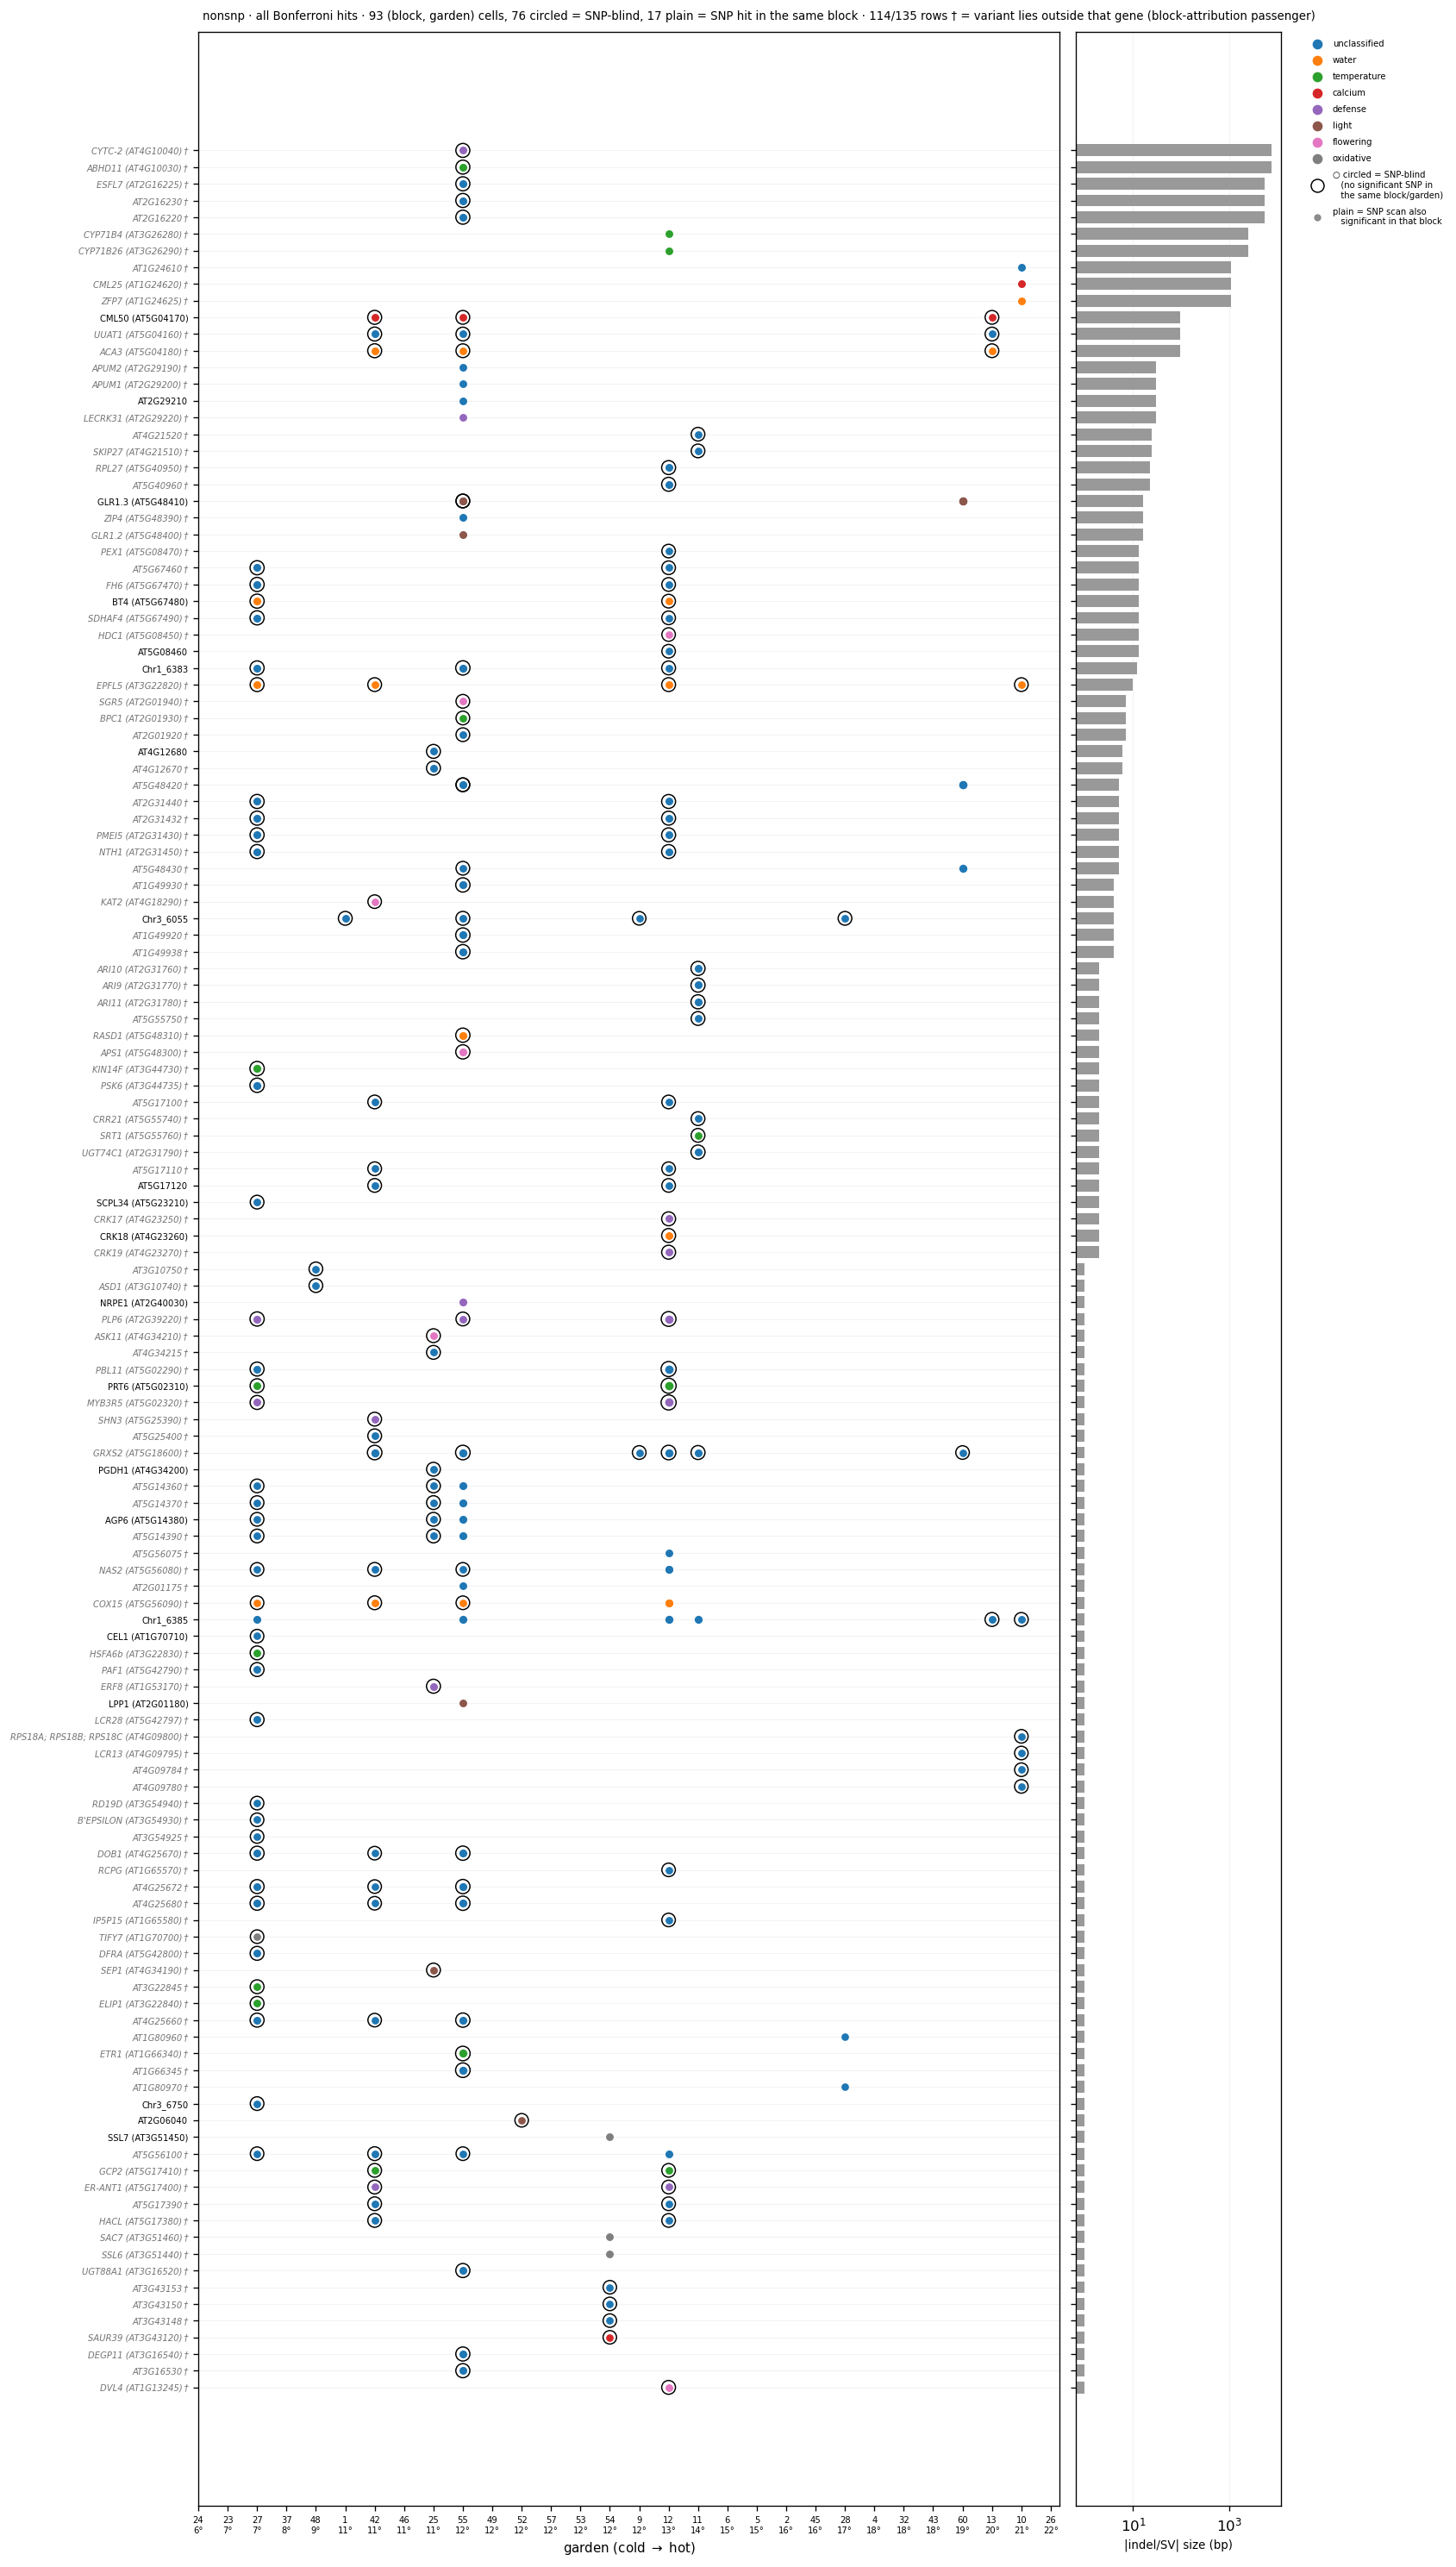

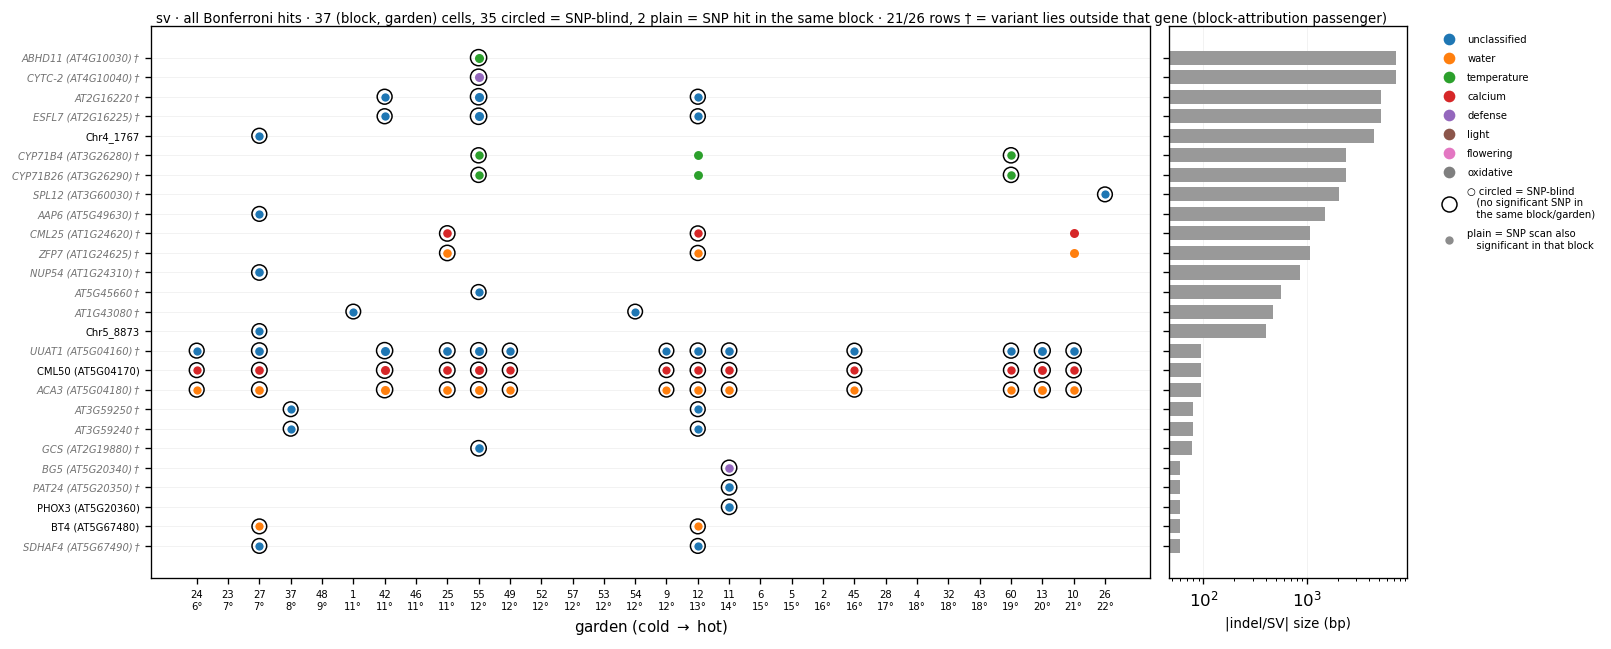

In [6]:

RING_AREA = 3.2            # ring marker AREA multiple -> ring radius ~1.8x the dot radius
CAT_ORDER = [c for c in ALL.category.value_counts().index]
PAL = plt.cm.tab10.colors + plt.cm.Set3.colors
CCOL = {c: PAL[i % len(PAL)] for i, c in enumerate(CAT_ORDER)}
xpos = {s: i for i, s in enumerate(site_order)}

for CLS in ["nonsnp", "sv"]:
    sub = ALL[ALL.cls == CLS]
    if not len(sub):
        print(f"no {CLS} Bonferroni hits to plot"); continue
    # rows ordered by |variant size| (largest at top), matching the reference dot grid
    gsz = sub.groupby("gene").size_bp.max().fillna(0).sort_values()
    gord = list(gsz.index)
    yidx = {g: i for i, g in enumerate(gord)}
    h = max(3.2, 0.23 * len(gord))
    fig, (ax, axr) = plt.subplots(1, 2, figsize=(13.5, h), sharey=True,
                                  gridspec_kw={"width_ratios": [4.2, 1], "wspace": 0.03})
    # every hit is the SAME solid dot; SNP-blindness is an OVERLAID open ring, not a fade.
    # Idiom taken from _build_persite_new_peaks_sv_nb.py::recurrence().
    for _, r in sub.iterrows():
        d = 12 + r.nlp * 2.2
        ax.scatter(xpos[r.garden], yidx[r.gene], s=d, c=[CCOL[r.category]],
                   linewidths=0, zorder=3)
        if not r.snp_also:
            ax.scatter(xpos[r.garden], yidx[r.gene], s=d * RING_AREA, facecolors="none",
                       edgecolors="black", linewidths=0.9, zorder=4)
    ax.set_xticks(range(len(site_order)))
    ax.set_xticklabels([f"{s}\n{site_bio1[s]:.0f}\u00b0" for s in site_order], fontsize=6)
    # y labels: SYMBOL (AGI) where a usable symbol exists, bare AGI/block id otherwise.
    # A trailing dagger + grey italic = every lead variant on that row falls OUTSIDE the gene
    # body, i.e. the row exists only by block attribution (a passenger, not its own locus).
    lab = sub.drop_duplicates("gene").set_index("gene")
    passeng = {g: (lab.loc[g, "has_gene"] and not sub[sub.gene == g].in_gene.any()) for g in gord}
    ax.set_yticks(range(len(gord)))
    ax.set_yticklabels([f"{lab.loc[g, 'label']}\u2009\u2020" if passeng[g] else lab.loc[g, "label"]
                        for g in gord], fontsize=6)
    for g, t in zip(gord, ax.get_yticklabels()):
        if passeng[g]:
            t.set_color("0.45"); t.set_style("italic")
    ax.set_xlabel("garden (cold $\\rightarrow$ hot)", fontsize=9)
    ax.grid(axis="y", lw=0.3, color="0.9", zorder=0)
    ax.set_axisbelow(True)
    ncell = sub.drop_duplicates(["blk", "garden"])
    ax.annotate(f"{CLS} \u00b7 all Bonferroni hits \u00b7 {len(ncell)} (block, garden) cells, "
                f"{int((~ncell.snp_also).sum())} circled = SNP-blind, "
                f"{int(ncell.snp_also.sum())} plain = SNP hit in the same block "
                f"\u00b7 {sum(passeng.values())}/{len(gord)} rows \u2020 = variant lies outside "
                f"that gene (block-attribution passenger)",
                xy=(0.005, 1.005), xycoords="axes fraction", fontsize=8)
    sizes = gsz.reindex(gord).fillna(0).to_numpy()
    axr.barh(range(len(gord)), np.maximum(sizes, 1), height=0.72, color="0.6")
    axr.set_xscale("log"); axr.set_xlabel("|indel/SV| size (bp)", fontsize=8)
    axr.grid(axis="x", lw=0.3, color="0.9"); axr.set_axisbelow(True)
    handles = [mlines.Line2D([], [], marker="o", ls="", ms=6, color=CCOL[c], label=c)
               for c in CAT_ORDER]
    handles += [mlines.Line2D([], [], marker="o", ls="", ms=9, mfc="none", mec="black", mew=0.9,
                              label="\u25cb circled = SNP-blind\n   (no significant SNP in\n   the same block/garden)"),
                mlines.Line2D([], [], marker="o", ls="", ms=5, mfc="0.55", mec="none",
                              label="plain = SNP scan also\n   significant in that block")]
    ax.legend(handles=handles, fontsize=6, loc="upper left", bbox_to_anchor=(1.28, 1.0),
              frameon=False, labelspacing=0.9)
    fig.savefig(f"{PLOTS}/persite_dotgrid_allhits_{CLS}.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close(fig)
